# Lezione 5 — Radiometria: da Planck alla potenza raccolta

Modulo *Radiazione termica e segnatura IR* (Master OQI, prof. R. Li Voti).

Si rifanno i due conti che chiudono la teoria del corpo nero, poi si passa
alle grandezze che servono davanti a un rivelatore: angolo solido, emittanza,
radianza, potenza in una banda. Il risultato che conta per la segnatura è
quanto contrasto resta, a temperatura ambiente, nella finestra 8–12 μm
rispetto alla 3–5 μm.

Notebook precedente: `04_lezione_corpo_nero.ipynb`.


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.4, 4.7),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.unicode_minus": False,
})
np.set_printoptions(precision=4, suppress=True)
print("Ambiente pronto.")

from scipy import constants
from scipy.optimize import brentq

H = constants.h
C = constants.c
K_B = constants.k
SIGMA = constants.sigma

def planck(lam, T):
    lam = np.asarray(lam, dtype=float)
    x = H * C / (lam * K_B * T)
    out = np.zeros_like(x)
    ok = (x > 0) & (x < 700)
    out[ok] = 2 * np.pi * H * C**2 / lam[ok]**5 / np.expm1(x[ok])
    return out

def potenza_banda(T, lam1, lam2, n=2500):
    lam = np.geomspace(lam1, lam2, n)
    return np.trapezoid(planck(lam, T), lam)


Ambiente pronto.


## 1. Il massimo di Planck, senza citarlo a memoria

Si pone \(x=hc/(\lambda k_B T)\). L'emittanza spettrale è proporzionale a
\(x^5/(e^x-1)\) a temperatura fissata, e la derivata si annulla quando

\[
(5-x)\,e^{x} = 5.
\]

La funzione \(5(1-e^{-x})-x\) attraversa lo zero una volta sola, a
\(x=4{,}9651\). Da lì

\[
\lambda_\mathrm{max} T = \frac{hc}{k_B x} = 2898\,\mu\mathrm{m\cdot K}.
\]


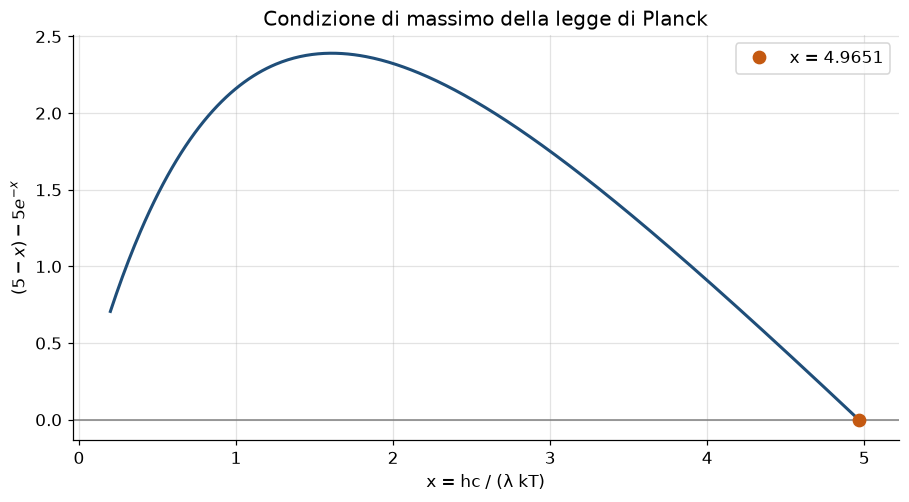

λ_max T = 2897.77 μm·K
37 °C, pelle         λ_max =   9.34 μm
300 K, ambiente      λ_max =   9.66 μm
lampada 3000 K       λ_max =   0.97 μm
Sole 5780 K          λ_max =   0.50 μm


In [2]:
def condizione(x):
    return (5 - x) * np.exp(x) - 5

x = np.linspace(0.2, 4.98, 500)
fig, ax = plt.subplots()
ax.plot(x, condizione(x) * np.exp(-x), color="#1f4e79", lw=2)
ax.axhline(0.0, color="0.5", lw=1)
x_star = brentq(condizione, 1.0, 4.98)
ax.plot(x_star, 0.0, "o", color="#c45911", ms=8, label=f"x = {x_star:.4f}")
ax.set_xlabel("x = hc / (λ kT)")
ax.set_ylabel(r"$(5-x) - 5 e^{-x}$")
ax.set_title("Condizione di massimo della legge di Planck")
ax.legend()
fig.tight_layout()
plt.show()

b = H * C / (K_B * x_star)
print(f"λ_max T = {b*1e6:.2f} μm·K")
assert np.isclose(x_star, 4.965114, atol=1e-4)

tabella = [("37 °C, pelle", 37 + 273.15), ("300 K, ambiente", 300),
           ("lampada 3000 K", 3000), ("Sole 5780 K", 5780)]
for nome, T in tabella:
    print(f"{nome:20} λ_max = {b/T*1e6:6.2f} μm")


## 2. L'integrale che produce \(\sigma\)

Con la stessa \(x\),

\[
\int_0^\infty M_\lambda\,d\lambda
= \frac{2\pi k_B^4}{h^3 c^2}\,T^4
\int_0^\infty \frac{x^3}{e^x-1}\,dx.
\]

L'integrale vale \(\pi^4/15\). Quindi

\[
\sigma = \frac{2\pi^5 k_B^4}{15\, c^2 h^3}.
\]


In [3]:
def integrando(x):
    # x^3 / (e^x - 1). Per x piccolo il limite è x^2.
    x = np.asarray(x, dtype=float)
    out = np.empty_like(x)
    piccolo = x < 1e-4
    out[piccolo] = x[piccolo] ** 2
    out[~piccolo] = x[~piccolo] ** 3 / np.expm1(x[~piccolo])
    return out

x = np.linspace(1e-4, 20, 20000)
integrale = np.trapezoid(integrando(x), x)
atteso = np.pi**4 / 15
print(f"integrale numerico = {integrale:.6f}")
print(f"π⁴/15              = {atteso:.6f}")
assert np.isclose(integrale, atteso, rtol=1e-4)

sigma = 2 * np.pi**5 * K_B**4 / (15 * C**2 * H**3)
print(f"σ calcolata = {sigma:.6e} W m⁻² K⁻⁴")
print(f"σ tabella   = {SIGMA:.6e} W m⁻² K⁻⁴")
assert np.isclose(sigma, SIGMA, rtol=1e-12)


integrale numerico = 6.493920
π⁴/15              = 6.493939
σ calcolata = 5.670374e-08 W m⁻² K⁻⁴
σ tabella   = 5.670374e-08 W m⁻² K⁻⁴


## 3. Angolo solido e superficie lambertiana

L'angolo solido sotto cui si vede un'areola \(dA\) da distanza \(r\),
inclinata di \(\theta\) rispetto alla linea di vista, è

\[
d\Omega = \frac{dA\cos\theta}{r^2}.
\]

Tutto l'emisfero vale \(2\pi\) steradianti (la sfera intera \(4\pi\)).

Una superficie lambertiana ha radianza \(L\) indipendente dalla direzione.
La sua emittanza, integrata sul mezzo spazio con il coseno, è

\[
M = \pi L.
\]

Il fattore è \(\pi\), non \(2\pi\): il coseno di Lambert toglie un fattore due.
Per il corpo nero \(L_\lambda = M_\lambda/\pi\), e \(M_\lambda\) è proprio la
formula di Planck scritta nelle slide.


In [4]:
# Emisfero: ∫ cosθ dΩ = ∫_0^{2π} dφ ∫_0^{π/2} cosθ sinθ dθ = π.
theta = np.linspace(0, np.pi / 2, 1000)
peso = np.sin(theta) * np.cos(theta)
integrale_angolo = 2 * np.pi * np.trapezoid(peso, theta)
print(f"∫_emisfero cosθ dΩ = {integrale_angolo:.6f}   (atteso π = {np.pi:.6f})")
assert np.isclose(integrale_angolo, np.pi, rtol=1e-5)

# Potenza che un rivelatore raccoglie da una faccia lambertiana, in asse.
# d²P = L cosθ_s cosθ_d dA_s dA_d / r². In asse, angoli nulli: P = L A_s A_d / r².
T = 310.0
A_s = 1.0e-4     # 1 cm² di pelle
A_d = 1.0e-6     # rivelatore da 1 mm²
r = 0.50         # m
L_tot = SIGMA * T**4 / np.pi
P = L_tot * A_s * A_d / r**2
print(f"Corpo nero a 37 °C, 1 cm² visto da 1 mm² a 50 cm: P = {P*1e9:.2f} nW")
print(f"Di cui nella banda 8–12 μm: {potenza_banda(T, 8e-6, 12e-6)/SIGMA/T**4*100:.1f}% dello spettro,")
print(f"cioè {P * potenza_banda(T, 8e-6, 12e-6) / (SIGMA*T**4) * 1e9:.2f} nW.")


∫_emisfero cosθ dΩ = 3.141590   (atteso π = 3.141593)
Corpo nero a 37 °C, 1 cm² visto da 1 mm² a 50 cm: P = 66.68 nW
Di cui nella banda 8–12 μm: 27.1% dello spettro,
cioè 18.05 nW.


## 4. Il contrasto che una termocamera può vedere

A temperatura ambiente il picco di Wien è vicino a 10 μm, dentro la finestra
atmosferica 8–12 μm (LWIR). La finestra 3–5 μm (MWIR) sta sulla coda di Wien:
ci arriva poca potenza, e un grado di differenza pesa meno.

Si confrontano due corpi neri, 37 °C e 20 °C, e anche la derivata
\(\partial M/\partial T\) a 300 K, che è la sensibilità della banda a un piccolo
\(\Delta T\).


banda                   M(37°C)      M(20°C)  contrasto  dM/dT a 300 K
MWIR 3–5 μm                8.38         4.55     84.21%          0.213
LWIR 8–12 μm             142.06       107.86     31.70%          1.978
tutto lo spettro         524.38       418.48     25.31%          6.123


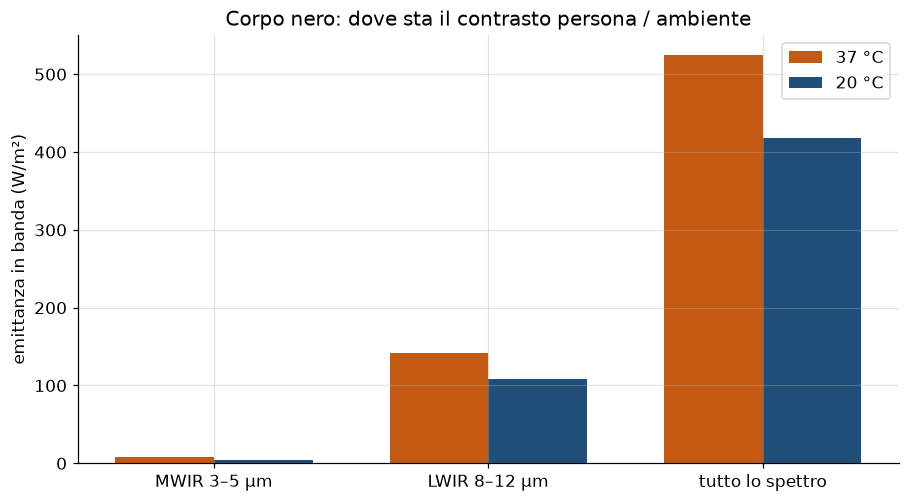


Un kelvin a 300 K pesa 9.3 volte di più in LWIR che in MWIR.


In [5]:
bande = {
    "MWIR 3–5 μm": (3e-6, 5e-6),
    "LWIR 8–12 μm": (8e-6, 12e-6),
    "tutto lo spettro": (0.3e-6, 200e-6),
}
T_obj, T_bg = 37 + 273.15, 20 + 273.15

print(f"{'banda':18} {'M(37°C)':>12} {'M(20°C)':>12} {'contrasto':>10} {'dM/dT a 300 K':>14}")
righe = []
for nome, (a, b_) in bande.items():
    Mo = potenza_banda(T_obj, a, b_)
    Mb = potenza_banda(T_bg, a, b_)
    # derivata centrata, ΔT = 0,2 K
    dT = 0.2
    dMdT = (potenza_banda(300 + dT, a, b_) - potenza_banda(300 - dT, a, b_)) / (2 * dT)
    contrasto = (Mo - Mb) / Mb
    righe.append((nome, Mo, Mb, contrasto, dMdT))
    print(f"{nome:18} {Mo:12.2f} {Mb:12.2f} {contrasto:10.2%} {dMdT:14.3f}")

nomi = [r[0] for r in righe]
fig, ax = plt.subplots()
x = np.arange(len(nomi))
ax.bar(x - 0.18, [r[1] for r in righe], width=0.36, label="37 °C", color="#c45911")
ax.bar(x + 0.18, [r[2] for r in righe], width=0.36, label="20 °C", color="#1f4e79")
ax.set_xticks(x, nomi)
ax.set_ylabel("emittanza in banda (W/m²)")
ax.set_title("Corpo nero: dove sta il contrasto persona / ambiente")
ax.legend()
fig.tight_layout()
plt.show()

# La LWIR, a 300 K, è molto più sensibile a un grado della MWIR.
sens_lwir = righe[1][4]
sens_mwir = righe[0][4]
print(f"\nUn kelvin a 300 K pesa {sens_lwir/sens_mwir:.1f} volte di più in LWIR che in MWIR.")


## 5. Grigio e selettivo, in potenza raccolta

La potenza emessa da un'area \(A\) è \(\varepsilon A\sigma T^4\) solo se
\(\varepsilon\) è costante. Per un selettivo si integra \(\varepsilon_\lambda M_\lambda\).
Un emissore tagliato sulla 8–12 μm butta via gran parte della potenza totale,
ma nella banda della termocamera resta quasi quanto un grigio con lo stesso
\(\varepsilon\) di picco: è l'idea dei rivestimenti selettivi che tornano nell'ultima lezione.


In [6]:
T = 310.0
A = 1.0   # m²
lam = np.geomspace(2e-6, 40e-6, 3000)
M = planck(lam, T)
eps_sel = np.where((lam >= 8e-6) & (lam <= 12e-6), 0.90, 0.05)

P_bb = A * SIGMA * T**4
P_grigio = 0.90 * P_bb
P_sel = A * np.trapezoid(eps_sel * M, lam)
P_lwir_bb = A * potenza_banda(T, 8e-6, 12e-6)
P_lwir_sel = A * np.trapezoid(np.where((lam >= 8e-6) & (lam <= 12e-6), 0.90 * M, 0.0), lam)

print(f"Corpo nero, totale          {P_bb:7.1f} W")
print(f"Grigio ε=0,9, totale        {P_grigio:7.1f} W")
print(f"Selettivo 8–12 μm, totale   {P_sel:7.1f} W")
print(f"Corpo nero, solo 8–12 μm    {P_lwir_bb:7.1f} W")
print(f"Selettivo, solo 8–12 μm     {P_lwir_sel:7.1f} W")


Corpo nero, totale            523.7 W
Grigio ε=0,9, totale          471.3 W
Selettivo 8–12 μm, totale     145.3 W
Corpo nero, solo 8–12 μm      141.7 W
Selettivo, solo 8–12 μm       127.6 W


## In sintesi

- Il massimo di Planck è la radice di \((5-x)e^x=5\): \(x=4{,}9651\), \(\lambda T=2898\,\mu\mathrm{m\cdot K}\).
- \(\int_0^\infty x^3/(e^x-1)\,dx=\pi^4/15\) produce la \(\sigma\) misurata, cifre comprese.
- Per una superficie lambertiana \(M=\pi L\), e l'emisfero «pesa» \(\pi\) e non \(2\pi\).
- Fra 37 °C e 20 °C il contrasto utile sta nella 8–12 μm. A 300 K un grado produce diversi W/m² in LWIR e una frazione di W/m² in MWIR: è il motivo per cui i microbolometri non raffreddati della lezione 6 lavorano nel lontano infrarosso.
